In [1]:
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# Load prepared dataset
data = joblib.load("Dataset/cycle_time_data.joblib")

df = data["df"]
Xraw = data["Xraw"]
yraw = data["yraw"]
FEATURES = data["features"]
TRAIN_END = data["train_end"]

# Experiment configuration
WINDOW = 10
LSTM_UNITS = 50
LR = 0.001
BATCH = 32

# ADWIN configuration
ADWIN_DELTA = 0.002
RETRAIN_WINDOW = 100
RETRAIN_EPOCHS = 15

# Same architecture as standalone LSTM
class LSTMReg(nn.Module):

    def __init__(self, n_feat, hidden=50):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=n_feat,
            hidden_size=hidden,
            batch_first=True
        )

        self.out = nn.Linear(hidden, 1)

    def forward(self, x):
        h, _ = self.lstm(x)
        return self.out(h[:, -1, :])


# Load trained baseline model
adaptive = LSTMReg(
    n_feat=len(FEATURES),
    hidden=LSTM_UNITS
)

adaptive.load_state_dict(
    torch.load(
        "Results/LSTM/lstm_model.pth",
        map_location="cpu",
        weights_only=True
    )
)

adaptive.eval()

# Load training scalers
scalers = joblib.load(
    "Results/LSTM/lstm_scalers.joblib"
)

sx = scalers["sx"]
sy = scalers["sy"]

print("Dataset:", df.shape)
print("Adaptive LSTM loaded successfully!")
print("ADWIN delta:", ADWIN_DELTA)
print("Retraining window:", RETRAIN_WINDOW)

Dataset: (995, 18)
Adaptive LSTM loaded successfully!
ADWIN delta: 0.002
Retraining window: 100


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


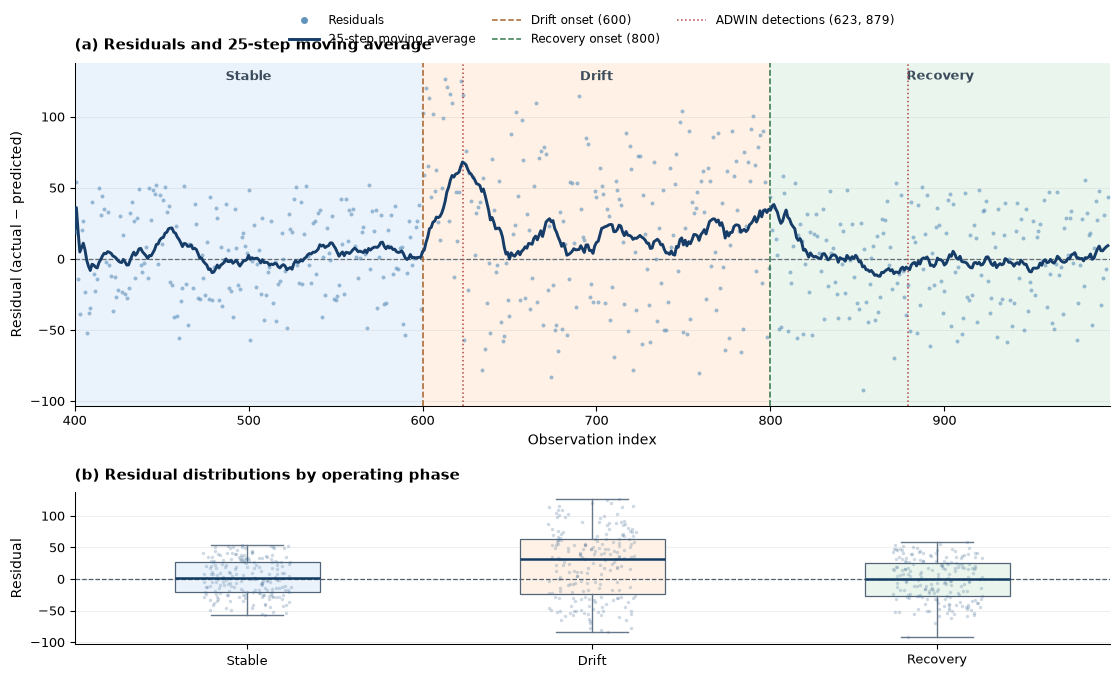

   Phase   N  Mean  Median    SD   IQR  Positive (%)
  Stable 200  3.00    1.18 28.36 47.61         52.00
   Drift 200 23.36   32.11 52.97 86.41         64.00
Recovery 195 -0.67    0.61 32.62 52.79         50.26

Saved: Figure\Figure5_residual_journal_quality.pdf, Figure\Figure5_residual_journal_quality.eps, Figure\Figure5_residual_journal_quality.png


In [1]:
# Figure 5 — publication-quality residual analysis
# Run this entire script in one JupyterLab cell.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# --- Settings ---
CSV_PATH = Path('Results/LSTM_ADWIN/lstm_adwin_predictions.csv')
if not CSV_PATH.exists():
    CSV_PATH = Path('lstm_adwin_predictions.csv')
if not CSV_PATH.exists():
    raise FileNotFoundError('Place lstm_adwin_predictions.csv in the notebook folder or Results/LSTM_ADWIN/.')
OUT = Path('Figure')
OUT.mkdir(parents=True, exist_ok=True)

# True vector paths and fonts in PDF/EPS
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.titlesize': 11, 'axes.labelsize': 10,
    'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'legend.fontsize': 8.5, 'axes.linewidth': 0.75,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
    'savefig.facecolor': 'white',
})

# --- Read data and calculate residuals ---
df = pd.read_csv(CSV_PATH).sort_values('idx').reset_index(drop=True)
required = {'idx', 'actual', 'predicted'}
if not required.issubset(df.columns):
    raise ValueError(f'Missing columns: {required - set(df.columns)}')
df['residual'] = df['actual'] - df['predicted']
df['moving_mean'] = df['residual'].rolling(window=25, min_periods=1).mean()

# Phase boundaries and detector outputs verified in LSTM+ADWIN notebook
phases = [('Stable', 400, 600, '#eaf2fb'),
          ('Drift', 600, 800, '#fff1e5'),
          ('Recovery', 800, 995, '#eaf5ed')]
detections = [623, 879]

fig, (ax, bx) = plt.subplots(
    2, 1, figsize=(11.5, 7.0),
    gridspec_kw={'height_ratios': [2.25, 1.0], 'hspace': 0.35},
    constrained_layout=False
)
fig.subplots_adjust(left=0.085, right=0.985, top=0.92, bottom=0.09)

# Panel A — residual series
for name, lo, hi, color in phases:
    ax.axvspan(lo, hi, color=color, zorder=0)
    ax.text((lo + hi) / 2, 0.98, name, transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=9, fontweight='bold', color='#3c4c5c')
ax.axhline(0, color='#515d68', lw=0.9, linestyle='--', zorder=1)
ax.scatter(df['idx'], df['residual'], s=8, color='#6194bd', alpha=0.62,
           linewidths=0, rasterized=False, zorder=2)
ax.plot(df['idx'], df['moving_mean'], color='#163c68', lw=2.1, zorder=4)
for x, color, style in [(600, '#a8672d', '--'), (800, '#38784d', '--')]:
    ax.axvline(x, color=color, lw=1.15, ls=style, zorder=3)
for x in detections:
    ax.axvline(x, color='#b34646', lw=1.1, ls=':', zorder=3)
ax.set_xlim(400, 995)
ax.set_ylabel('Residual (actual − predicted)')
ax.set_xlabel('Observation index')
ax.set_title('(a) Residuals and 25-step moving average', loc='left', fontweight='bold', pad=10)
ax.grid(axis='y', alpha=0.20, lw=0.7)
ax.spines[['top', 'right']].set_visible(False)
handles = [
    Line2D([0], [0], marker='o', color='none', markerfacecolor='#6194bd',
           markeredgecolor='none', markersize=5, label='Residuals'),
    Line2D([0], [0], color='#163c68', lw=2.1, label='25-step moving average'),
    Line2D([0], [0], color='#a8672d', ls='--', lw=1.1, label='Drift onset (600)'),
    Line2D([0], [0], color='#38784d', ls='--', lw=1.1, label='Recovery onset (800)'),
    Line2D([0], [0], color='#b34646', ls=':', lw=1.1, label='ADWIN detections (623, 879)')
]
ax.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 1.02),
          ncol=3, frameon=False, columnspacing=1.4, handlelength=2.5)

# Panel B — distributions, no outliers hidden (scatter all observations)
values = []
for _, lo, hi, _ in phases:
    values.append(df.loc[(df.idx >= lo) & (df.idx < hi), 'residual'].to_numpy())
box = bx.boxplot(values, positions=[1, 2, 3], widths=0.42, patch_artist=True,
                 showfliers=False, medianprops={'color':'#123c63','linewidth':1.8},
                 whiskerprops={'color':'#667789'}, capprops={'color':'#667789'},
                 boxprops={'edgecolor':'#526477','linewidth':0.9})
for patch, (_, _, _, color) in zip(box['boxes'], phases):
    patch.set_facecolor(color)
# All observations shown as low-opacity jitter; fixed RNG for reproducibility
rng = np.random.default_rng(42)
for j, vals in enumerate(values, 1):
    jitter = rng.uniform(-0.13, 0.13, len(vals))
    bx.scatter(j + jitter, vals, s=6, alpha=0.26, color='#456f96',
               linewidths=0, rasterized=False, zorder=2)
bx.axhline(0, color='#515d68', lw=0.9, ls='--')
bx.set_xticks([1, 2, 3], ['Stable', 'Drift', 'Recovery'])
bx.set_ylabel('Residual')
bx.set_title('(b) Residual distributions by operating phase', loc='left',
             fontweight='bold', pad=9)
bx.grid(axis='y', alpha=0.20, lw=0.7)
bx.spines[['top', 'right']].set_visible(False)

# Save with native vector objects (do not rasterize points)
base = OUT / 'Figure5_residual_journal_quality'
fig.savefig(base.with_suffix('.pdf'), bbox_inches='tight')
fig.savefig(base.with_suffix('.eps'), bbox_inches='tight')
fig.savefig(base.with_suffix('.png'), dpi=600, bbox_inches='tight')
plt.show()
plt.close(fig)

# Print the statistics that can be cited in the manuscript
rows = []
for name, lo, hi, _ in phases:
    v = df.loc[(df.idx >= lo) & (df.idx < hi), 'residual']
    rows.append({'Phase': name, 'N': len(v), 'Mean': v.mean(),
                 'Median': v.median(), 'SD': v.std(ddof=1),
                 'IQR': v.quantile(.75) - v.quantile(.25),
                 'Positive (%)': 100 * (v > 0).mean()})
print(pd.DataFrame(rows).round(2).to_string(index=False))
print(f'\nSaved: {base}.pdf, {base}.eps, {base}.png')


In [3]:
from river.drift import ADWIN

# Initialize ADWIN
adwin = ADWIN(delta=ADWIN_DELTA)

print("ADWIN initialized successfully!")
print("Delta:", adwin.delta)
print("Drift detected:", adwin.drift_detected)

ADWIN initialized successfully!
Delta: 0.002
Drift detected: False


In [4]:
import random
from sklearn.preprocessing import StandardScaler

def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def make_seq(X, y, end_idx_list, window=10):
    Xs = []
    ys = []

    for i in end_idx_list:
        Xs.append(X[i-window:i])
        ys.append(y[i])

    return (
        np.array(Xs, dtype=np.float32),
        np.array(ys, dtype=np.float32)
    )


def fit(model, X, y, epochs=15, seed=0):

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LR
    )

    loss_fn = nn.MSELoss()

    X_tensor = torch.tensor(X, dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.float32)

    generator = torch.Generator()
    generator.manual_seed(seed)

    for epoch in range(epochs):

        model.train()

        order = torch.randperm(
            len(X_tensor),
            generator=generator
        )

        for start in range(0, len(X_tensor), BATCH):

            idx = order[start:start+BATCH]

            optimizer.zero_grad()

            prediction = model(X_tensor[idx])
            loss = loss_fn(prediction, y_tensor[idx])

            loss.backward()
            optimizer.step()

    model.eval()


def retrain_adaptive_model(model, current_idx, seed=0):

    # Include current observation after its actual value is known
    end = current_idx + 1
    start = max(0, end - RETRAIN_WINDOW)

    # Fit new scalers on recent observations
    new_sx = StandardScaler().fit(Xraw[start:end])
    new_sy = StandardScaler().fit(
        yraw[start:end].reshape(-1, 1)
    )

    # Transform available observations
    X_scaled = new_sx.transform(Xraw[:end])
    y_scaled = new_sy.transform(
        yraw[:end].reshape(-1, 1)
    )

    # Training sequences with targets inside the recent window
    X_train, y_train = make_seq(
        X_scaled,
        y_scaled,
        range(max(start, WINDOW), end),
        window=WINDOW
    )

    # Continue training existing model
    fit(
        model,
        X_train,
        y_train,
        epochs=RETRAIN_EPOCHS,
        seed=seed
    )

    return model, new_sx, new_sy

In [5]:
# Prediction function
def predict(model, X):
    model.eval()

    with torch.no_grad():
        X_tensor = torch.tensor(X, dtype=torch.float32)
        return model(X_tensor).numpy()


# Reset ADWIN before evaluation
adwin = ADWIN(delta=ADWIN_DELTA)

# Reset scalers to the original training scalers
scalers = joblib.load("Results/LSTM/lstm_scalers.joblib")
sx = scalers["sx"]
sy = scalers["sy"]

# Reload baseline model to ensure a fresh evaluation
adaptive = LSTMReg(
    n_feat=len(FEATURES),
    hidden=LSTM_UNITS
)

adaptive.load_state_dict(
    torch.load(
        "Results/LSTM/lstm_model.pth",
        map_location="cpu",
        weights_only=True
    )
)

adaptive.eval()

# Original training standard deviation
train_std = np.std(yraw[:TRAIN_END])

adaptive_results = []
drift_points = []

# Sequential evaluation
for i in range(TRAIN_END, len(yraw)):

    # Scale previous 10 observations
    X_test = sx.transform(
        Xraw[i-WINDOW:i]
    )[None]

    # Predict processing time
    pred_scaled = predict(adaptive, X_test)

    pred_original = sy.inverse_transform(
        pred_scaled
    )[0, 0]

    actual = float(yraw[i])

    # Record prediction before updating the model
    adaptive_results.append({
        "idx": i,
        "phase": df.loc[i, "phase"],
        "actual": actual,
        "predicted": float(pred_original)
    })

    # Calculate normalized squared error
    error = ((actual - pred_original) / train_std) ** 2

    # Update drift detector
    adwin.update(float(error))

    # Retrain when drift is detected
    if adwin.drift_detected and i >= 600:

        drift_points.append(i)

        print(f"Drift detected at observation {i}")

        adaptive, sx, sy = retrain_adaptive_model(
            adaptive,
            current_idx=i,
            seed=0
        )


# Convert results to DataFrame
adaptive_results_df = pd.DataFrame(adaptive_results)

print("\nEvaluation completed!")
print("Total predictions:", len(adaptive_results_df))
print("Detected drift points:", drift_points)

display(adaptive_results_df.head())

Drift detected at observation 623
Drift detected at observation 879

Evaluation completed!
Total predictions: 595
Detected drift points: [623, 879]


,idx,phase,actual,predicted
0,400,stable,87.0,68.765953
1,401,stable,120.0,66.073486
2,402,stable,54.0,67.864563
3,403,stable,31.0,69.677788
4,404,stable,93.0,72.810616


In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

def calculate_metrics(group):

    actual = group["actual"]
    predicted = group["predicted"]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    return pd.Series({
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2)
    })


# Calculate adaptive LSTM metrics
adaptive_metrics_df = adaptive_results_df.groupby(
    "phase", sort=False
).apply(calculate_metrics)

print("LSTM + ADWIN Performance:")
display(adaptive_metrics_df)

LSTM + ADWIN Performance:


,MAE,RMSE
phase,,
stable,24.28,28.44
drift,49.78,57.77
recovery,27.88,32.54


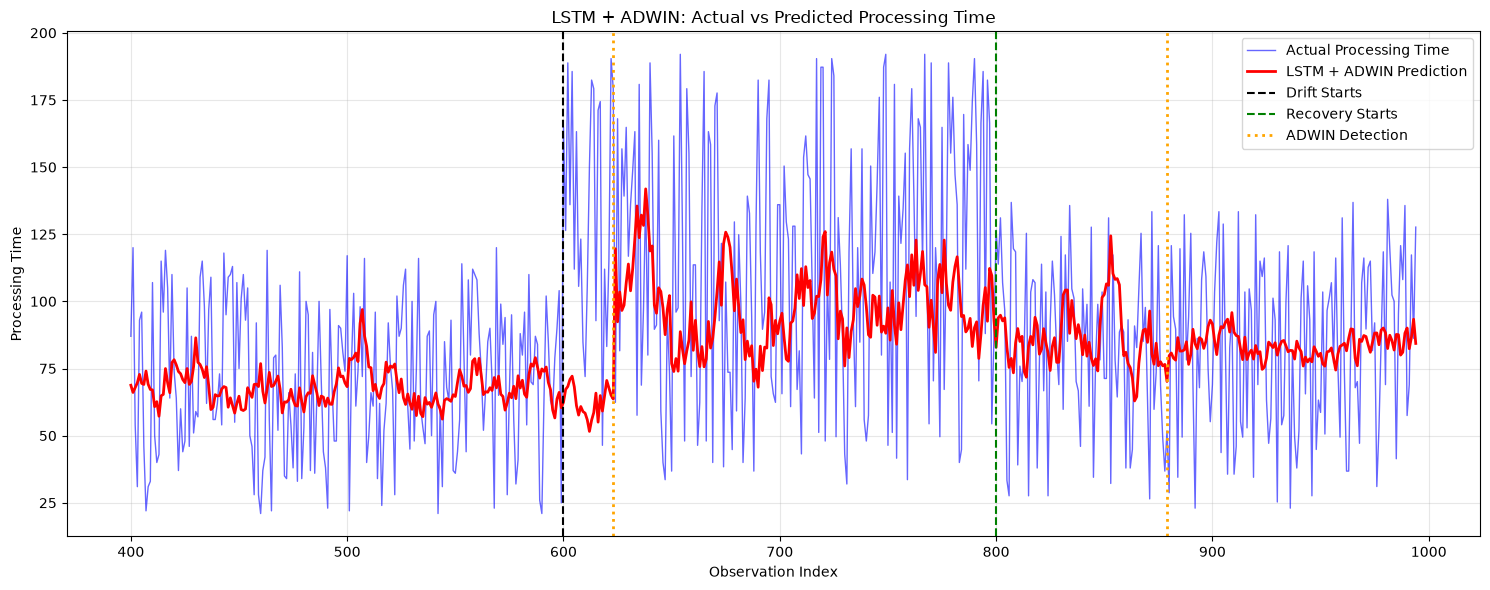

In [7]:
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("Results/LSTM_ADWIN")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def plot_adaptive_predictions(results_df, drift_points):

    fig, ax = plt.subplots(figsize=(15, 6))

    ax.plot(
        results_df["idx"],
        results_df["actual"],
        label="Actual Processing Time",
        color="blue",
        alpha=0.6,
        linewidth=1
    )

    ax.plot(
        results_df["idx"],
        results_df["predicted"],
        label="LSTM + ADWIN Prediction",
        color="red",
        linewidth=2
    )

    # Simulated operating changes
    ax.axvline(
        600, color="black",
        linestyle="--",
        label="Drift Starts"
    )

    ax.axvline(
        800, color="green",
        linestyle="--",
        label="Recovery Starts"
    )

    # ADWIN detections
    for j, point in enumerate(drift_points):
        ax.axvline(
            point,
            color="orange",
            linestyle=":",
            linewidth=2,
            label="ADWIN Detection" if j == 0 else None
        )

    ax.set_title("LSTM + ADWIN: Actual vs Predicted Processing Time")
    ax.set_xlabel("Observation Index")
    ax.set_ylabel("Processing Time")
    ax.legend()
    ax.grid(alpha=0.3)

    fig.tight_layout()

    # Save BEFORE displaying
    fig.savefig(
        OUTPUT_DIR / "lstm_adwin_actual_vs_predicted.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


plot_adaptive_predictions(adaptive_results_df, drift_points)

In [8]:
import json

# Save predictions
adaptive_results_df.to_csv(
    OUTPUT_DIR / "lstm_adwin_predictions.csv",
    index=False
)

# Save metrics
adaptive_metrics_df.to_csv(
    OUTPUT_DIR / "lstm_adwin_metrics.csv"
)

# Save detected drift points
with open(OUTPUT_DIR / "drift_detections.json", "w") as f:
    json.dump(
        {"detections": drift_points},
        f,
        indent=4
    )

# Save final adapted model and scalers
torch.save(
    adaptive.state_dict(),
    OUTPUT_DIR / "lstm_adwin_model.pth"
)

joblib.dump(
    {"sx": sx, "sy": sy},
    OUTPUT_DIR / "lstm_adwin_scalers.joblib"
)

print("LSTM + ADWIN results saved successfully!")

LSTM + ADWIN results saved successfully!
